In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.optim as optim

In [13]:
#Problem 1 Temperature Dataset from slides
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)
t_un = 0.1 * t_u

LEARNING_RATES = [0.1, 0.01, 0.001, 0.0001]


In [14]:
#functions
def model_linear(t_u, w, b):
    return w * t_u + b

# nonlinear model - w2 * t_u^2 + w1 * t_u + b
def model_nonlinear(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b

def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c)**2
    return squared_diffs.mean()

# training loop from slide w/ model passed so it works for both linear & nonlinear
def training_loop(n_epochs, optimizer, params, model, t_u, t_c):
    history = []
    for epoch in range(1, n_epochs + 1):
        t_p = model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss)))
            history.append(float(loss))
    return params, history


Learning rate = 0.1
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params: tensor([nan, nan, nan])

Learning rate = 0.01
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params: tensor([nan, nan, nan])

Learning rate = 0.001
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
params: tensor([nan, nan, nan])

Learning rate = 0.0001
Epoch 500, Loss 10.708596
Epoch 1000, Loss 8.642083
Epoch 1500, Loss 7.171005
Epoch 2000, Loss 6.123478
Epoch 2500, Loss 5.377227
Epoch 3000, Loss 4.845286
Epoch 3500, Loss 4.465788
Epoch

,0.1000,0.0100,0.0010,0.0001
Epoch,,,,
500,NaN,NaN,NaN,10.708596
1000,NaN,NaN,NaN,8.642083
1500,NaN,NaN,NaN,7.171005
2000,NaN,NaN,NaN,6.123478
2500,NaN,NaN,NaN,5.377227
3000,NaN,NaN,NaN,4.845286
3500,NaN,NaN,NaN,4.465788
4000,NaN,NaN,NaN,4.194724
4500,NaN,NaN,NaN,4.000802


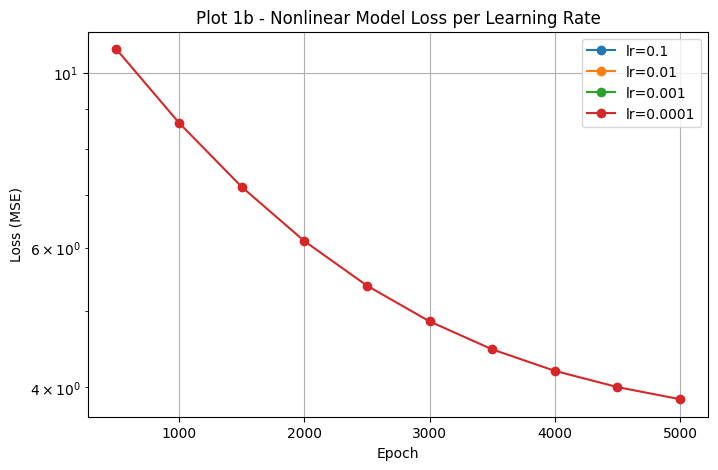

In [15]:
#Problem 1.a/b nonlinear training for each learning rate for 5000 epochs
results_1 = {}

for lr in LEARNING_RATES:
    print(f'\nLearning rate = {lr}')
    params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)   # w2, w1, b
    optimizer = optim.SGD([params], lr=lr)
    params, hist = training_loop(5000, optimizer, params, model_nonlinear, t_un, t_c)
    results_1[lr] = (params.detach().clone(), hist)
    print('params:', params.detach())

loss_table_1 = pd.DataFrame({lr: h for lr, (p, h) in results_1.items()}, index=range(500, 5001, 500))
loss_table_1.index.name = 'Epoch'
display(loss_table_1)


# loss curves per learn rate plotted
plt.figure(figsize=(8, 5))
for lr, (p, h) in results_1.items():
    plt.plot(range(500, 5001, 500), h, marker='o', label=f'lr={lr}')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Plot 1b - Nonlinear Model Loss per Learning Rate')
plt.legend()
plt.grid(True)
plt.show()


Epoch 500, Loss 7.860120
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647
Best nonlinear lr: 0.0001 | final loss: 3.8617441654205322 | params: tensor([ 0.5570, -0.8881, -0.8753])
Linear final loss: 2.9276468753814697 | params: tensor([  5.3671, -17.3012])


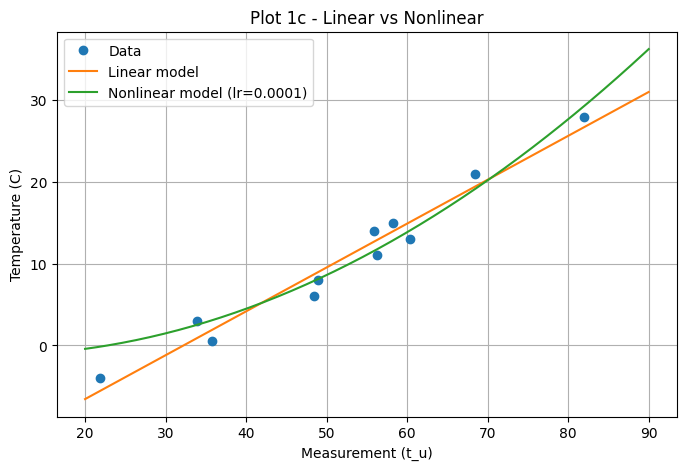

In [16]:
#Problem 1.c) baseline linear model to compare against best nonlinear model
params_lin = torch.tensor([1.0, 0.0], requires_grad=True)
optimizer = optim.SGD([params_lin], lr=1e-2)
params_lin, hist_lin = training_loop(5000, optimizer, params_lin, model_linear, t_un, t_c)

# best nonlinear final loss w/ best learning rate
nl = min([lr for lr in results_1 if np.isfinite(results_1[lr][1][-1])], key=lambda lr: results_1[lr][1][-1])
params_nl = results_1[nl][0]
print('Best nonlinear lr:', nl, '| final loss:', results_1[nl][1][-1], '| params:', params_nl)
print('Linear final loss:', hist_lin[-1], '| params:', params_lin.detach())

# plot both models over the input data
t_range = torch.linspace(20, 90, 200)
with torch.no_grad():
    lin_line = model_linear(0.1 * t_range, *params_lin)
    nl_line = model_nonlinear(0.1 * t_range, *params_nl)

plt.figure(figsize=(8, 5))
plt.plot(t_u.numpy(), t_c.numpy(), 'o', label='Data')
plt.plot(t_range.numpy(), lin_line.numpy(), label='Linear model')
plt.plot(t_range.numpy(), nl_line.numpy(), label=f'Nonlinear model (lr={nl})')

plt.xlabel('Measurement (t_u)')
plt.ylabel('Temperature (C)')
plt.title('Plot 1c - Linear vs Nonlinear')
plt.legend()
plt.grid(True)
plt.show()


In [17]:
#Problem 2 Housing Dataset Input
url = 'https://raw.githubusercontent.com/HamedTabkhi/Intro-to-ML/main/Dataset/Housing.csv'
df = pd.DataFrame(pd.read_csv(url))
for c in ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']:
    df[c] = df[c].map({'yes': 1, 'no': 0}).astype(int)

# 80/20 split
m = len(df)
np.random.seed(163)
mix_idx = np.random.permutation(m)
train_idx = mix_idx[:int(m*0.8)]  # 436 training rows
val_idx = mix_idx[int(m*0.8):]    # 109 validation rows

y_train_raw = df['price'].values[train_idx].astype(float)
y_val_raw = df['price'].values[val_idx].astype(float)

y_mean, y_std = y_train_raw.mean(), y_train_raw.std() #stanardized to prevent overflow

print("Rows:", m, "| train:", len(train_idx), "| validation:", len(val_idx))

Rows: 545 | train: 436 | validation: 109


In [18]:
#Housing data functions
def to_price(pred_s):
    return pred_s * y_std + y_mean

def model_housing(X, w, b):
    return X @ w + b



def prep_housing(cols):
    X_train_raw = df[cols].values[train_idx].astype(float)
    X_val_raw = df[cols].values[val_idx].astype(float)
    #standardization = (x - mean) / standard deviation, train stats only
    mean, std = X_train_raw.mean(axis=0), X_train_raw.std(axis=0)
    X_train = torch.tensor((X_train_raw - mean) / std, dtype=torch.float32)
    X_val = torch.tensor((X_val_raw - mean) / std, dtype=torch.float32)
    y_train = torch.tensor((y_train_raw - y_mean) / y_std, dtype=torch.float32)
    y_val = torch.tensor((y_val_raw - y_mean) / y_std, dtype=torch.float32)
    return X_train, X_val, y_train, y_val

def r2_score(y_true, y_pred):
    return 1 - ((y_true - y_pred)**2).sum() / ((y_true - y_true.mean())**2).sum()

# training loop w/ validation - loss + R2 every 500 epochs
def training_loop_val(n_epochs, optimizer, w, b, X_train, y_train, X_val, y_val):
    rows = []
    for epoch in range(1, n_epochs + 1):
        t_p = model_housing(X_train, w, b)
        loss = loss_fn(t_p, y_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                val_p = model_housing(X_val, w, b)
                val_loss = loss_fn(val_p, y_val)
                val_r2 = r2_score(y_val, val_p)
            print('Epoch %d, Train Loss %f, Val Loss %f, Val R2 %.4f' % (epoch, float(loss), float(val_loss), float(val_r2)))
            rows.append({'Epoch': epoch, 'Train Loss': float(loss), 'Val Loss': float(val_loss), 'Val R2': float(val_r2)})
    return w, b, pd.DataFrame(rows).set_index('Epoch')

# compares all 4 learning rates
def run_housing(cols, tag):
    X_train, X_val, y_train, y_val = prep_housing(cols)
    out = {}
    for lr in LEARNING_RATES:
        print(f'\n{tag} - Learning rate = {lr}')
        w = torch.zeros(len(cols), requires_grad=True)
        b = torch.zeros((), requires_grad=True)
        optimizer = optim.SGD([w, b], lr=lr)
        w, b, tbl = training_loop_val(5000, optimizer, w, b, X_train, y_train, X_val, y_val)
        out[lr] = (w.detach().clone(), b.detach().clone(), tbl)

    best_lr = min(out, key=lambda lr: out[lr][2]['Val Loss'].iloc[-1])
    w, b, tbl = out[best_lr]
    with torch.no_grad():
        val_price = to_price(model_housing(X_val, w, b).numpy())
        train_price = to_price(model_housing(X_train, w, b).numpy())
    rmse = np.sqrt(((val_price - y_val_raw)**2).mean())
    # same cost formula as hw2 (1/(2m) * sum, m = 545
    hw2_train_J = ((train_price - y_train_raw)**2).sum() / (2 * m)
    hw2_val_J = ((val_price - y_val_raw)**2).sum() / (2 * m)
    print(f'\n{tag} best lr = {best_lr}')
    print('w:', w.numpy(), ' b:', float(b))
    print(f'Val R2 = {r2_score(y_val_raw, val_price):.4f} | Val RMSE = ${rmse:,.0f}')
    print(f'HW2 format cost - train J = {hw2_train_J:.4f}, val J = {hw2_val_J:.4f}')

    plt.figure(figsize=(8, 5))
    for lr in LEARNING_RATES:
        plt.plot(out[lr][2].index, out[lr][2]['Val Loss'], marker='o', label=f'lr={lr}')
    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Validation Loss (standardized MSE)')
    plt.title(f'Plot {tag} - Validation Loss per Learning Rate')
    plt.legend()
    plt.grid(True)
    plt.show()
    return out, best_lr


2b - Learning rate = 0.1
Epoch 500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 1000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 1500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 2000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 2500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 3000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 3500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 4000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 4500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 5000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542

2b - Learning rate = 0.01
Epoch 500, Train Loss 0.408408, Val Loss 0.472559, Val R2 0.3542
Epoch 1000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 1500, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 2000, Train Loss 0.408408, Val Loss 0.472570, Val R2 0.3542
Epoch 2500, Train Loss 0.

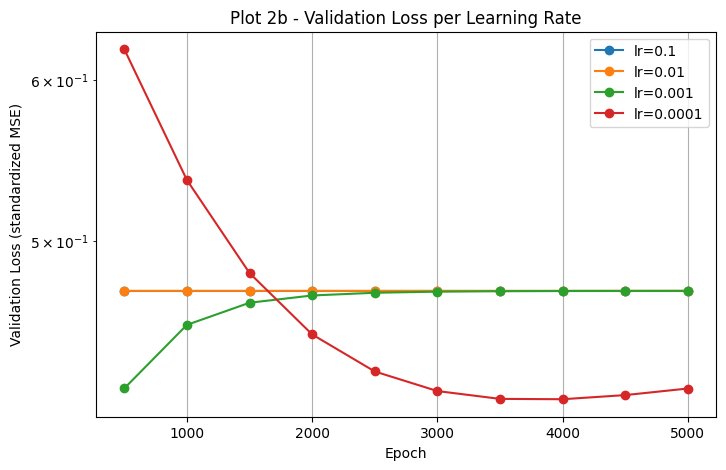

In [19]:
#Problem 2) area, bedrooms, bathrooms, stories, parking

vars_2 = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
out_2, best_lr_2 = run_housing(vars_2, '2b')



3b - Learning rate = 0.1
Epoch 500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 1000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 1500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 2000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 2500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 3000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 3500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 4000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 4500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 5000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114

3b - Learning rate = 0.01
Epoch 500, Train Loss 0.303932, Val Loss 0.357510, Val R2 0.5114
Epoch 1000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 1500, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 2000, Train Loss 0.303931, Val Loss 0.357547, Val R2 0.5114
Epoch 2500, Train Loss 0.

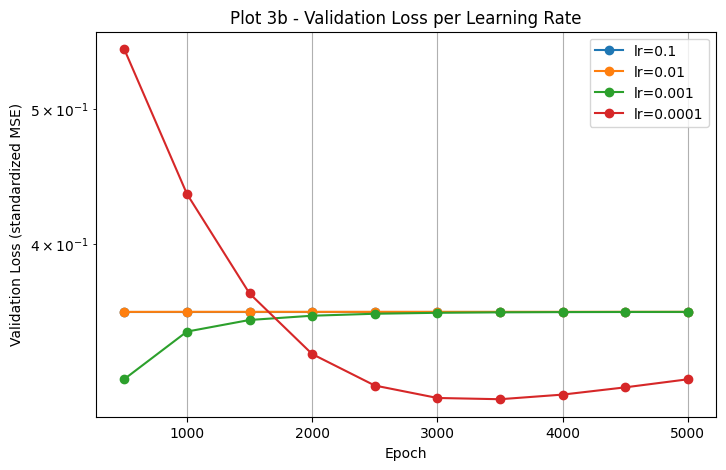

In [20]:
#Problem 3) all input features

vars_3 = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement',
          'hotwaterheating', 'airconditioning', 'parking', 'prefarea']
out_3, best_lr_3 = run_housing(vars_3, '3b')
